# 🦁 Introduction to YOLO — Animal Detection & Embeddings

This notebook is a hands-on introduction to **YOLO (You Only Look Once)** using a Kaggle animal image dataset.

### What you'll learn
1. **Setup** — install dependencies and authenticate with Kaggle
2. **Dataset** — download and explore the *Animals-10* image dataset
3. **Visualize** — display a random sample of 15 images
4. **YOLO Inference** — run YOLOv8 and draw detection bounding boxes
5. **Advanced** — extract YOLO embeddings, store them in a vector database (FAISS), and retrieve similar animals via cosine similarity

> 💡 **Runtime:** Go to `Runtime → Change runtime type` and select **GPU (T4)** for faster inference.


---
## 1. 🔧 Setup & Installation

In [ ]:
# Install required packages
!pip install ultralytics kaggle faiss-cpu Pillow matplotlib numpy -q
print("✅ Packages installed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 87.7 MB/s eta 0:00:00
✅ Packages installed


In [ ]:
!pip freeze > requirements.txt

In [ ]:
import os
import json
import random
import zipfile
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
from ultralytics import YOLO

import faiss

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"✅ Imports OK  |  Device: {device}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
✅ Imports OK  |  Device: cuda


---
## 2. 📦 Kaggle Authentication & Dataset Download

We use the [**Animals-10**](https://www.kaggle.com/datasets/alessiocorrado99/animals10) dataset — ~26 000 images across 10 animal classes: *dog, cat, horse, spider, butterfly, chicken, sheep, cow, squirrel, elephant*.

### How to get your Kaggle API key
1. Log in to [kaggle.com](https://www.kaggle.com) → **Account → Create New API Token**
2. A `kaggle.json` file will be downloaded to your computer.
3. Upload it using the cell below **or** paste your credentials manually.

In [ ]:
# ── Option A: Upload kaggle.json from your computer ──────────────────────────
from google.colab import files

print("Upload your kaggle.json file:")
uploaded = files.upload()  # A dialog will open — select kaggle.json

kaggle_dir = Path("/root/.config/kaggle")
kaggle_dir.mkdir(parents=True, exist_ok=True)
shutil.copy("kaggle.json", kaggle_dir / "kaggle.json")
os.chmod(kaggle_dir / "kaggle.json", 0o600)
print("✅ kaggle.json configured")

Upload your kaggle.json file:


Saving kaggle.json to kaggle.json
✅ kaggle.json configured


In [ ]:
# ── Option B: Paste credentials directly (alternative to Option A) ───────────
# Uncomment and fill in if you prefer not to upload the file.

# KAGGLE_USERNAME = "your_username_here"
# KAGGLE_KEY      = "your_api_key_here"
#
# kaggle_dir = Path("/root/.config/kaggle")
# kaggle_dir.mkdir(parents=True, exist_ok=True)
# (kaggle_dir / "kaggle.json").write_text(
#     json.dumps({"username": KAGGLE_USERNAME, "key": KAGGLE_KEY})
# )
# os.chmod(kaggle_dir / "kaggle.json", 0o600)
# print("✅ kaggle.json configured")

In [ ]:
DATA_DIR = Path("animals10")

if not DATA_DIR.exists():
    print("Downloading Animals-10 dataset (~600 MB) …")
    !kaggle datasets download -d alessiocorrado99/animals10 -p . --unzip -q
    print("✅ Download complete")
else:
    print("✅ Dataset already present — skipping download")

# Locate the 'raw-img' folder that contains per-class subdirectories
RAW_IMG_DIR = DATA_DIR / "raw-img"
if not RAW_IMG_DIR.exists():
    # Kaggle sometimes puts it at the top level
    RAW_IMG_DIR = Path("raw-img")

classes = sorted([d.name for d in RAW_IMG_DIR.iterdir() if d.is_dir()])
print(f"\n📂 Classes ({len(classes)}): {classes}")

Dataset URL: https://www.kaggle.com/datasets/alessiocorrado99/animals10
License(s): GPL-2.0
✅ Download complete

📂 Classes (10): ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']


In [ ]:
# Collect all image paths
IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

all_images = []
for cls in classes:
    class_dir = RAW_IMG_DIR / cls
    imgs = [p for p in class_dir.iterdir() if p.suffix.lower() in IMG_EXTENSIONS]
    all_images.extend(imgs)

random.shuffle(all_images)
print(f"✅ Total images found: {len(all_images):,}")

# Quick per-class count
from collections import Counter
class_counts = Counter(p.parent.name for p in all_images)
print("\nImages per class:")
for cls, cnt in sorted(class_counts.items()):
    bar = "█" * (cnt // 100)
    print(f"  {cls:<12} {cnt:>5}  {bar}")

✅ Total images found: 26,179

Images per class:
  cane          4863  ████████████████████████████████████████████████
  cavallo       2623  ██████████████████████████
  elefante      1446  ██████████████
  farfalla      2112  █████████████████████
  gallina       3098  ██████████████████████████████
  gatto         1668  ████████████████
  mucca         1866  ██████████████████
  pecora        1820  ██████████████████
  ragno         4821  ████████████████████████████████████████████████
  scoiattolo    1862  ██████████████████


---
## 3. 🖼️ Random Sample — 15 Images

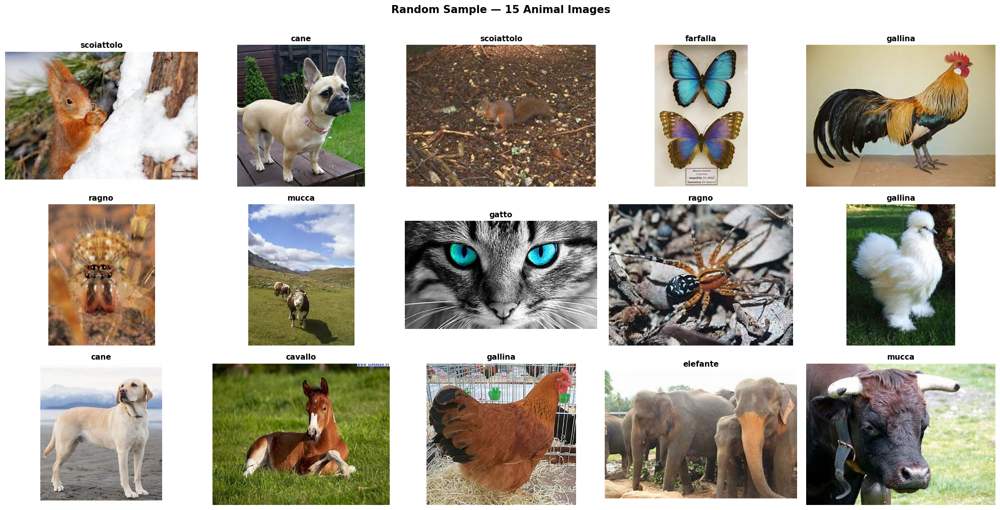

In [ ]:
def show_image_grid(image_paths, title="Sample Images", cols=5, figsize=(20, 10)):
    """Display a grid of images with their class labels."""
    n = len(image_paths)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten()

    for ax, img_path in zip(axes, image_paths):
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(img_path.parent.name, fontsize=11, fontweight="bold")
        ax.axis("off")

    # Hide unused axes
    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle(title, fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()


sample_15 = random.sample(all_images, 15)
show_image_grid(sample_15, title="Random Sample — 15 Animal Images")

---
## 4. 🤖 YOLO — Configuration & Inference

We use **YOLOv8** (Ultralytics) pre-trained on the **COCO** dataset, which already includes many of our animal classes (dog, cat, horse, cow, sheep, elephant, bear, zebra, giraffe, bird).

| Model | Size | mAP | Speed |
|-------|------|-----|-------|
| `yolov8n` | 3.2 MB | 37.3 | Fastest |
| `yolov8s` | 11.2 MB | 44.9 | Fast |
| `yolov8m` | 25.9 MB | 50.2 | Balanced |

We'll use `yolov8m` for a good accuracy/speed trade-off.

In [ ]:
# Load YOLOv8 medium — downloads weights (~25 MB) on first run
model = YOLO("yolov8m.pt")
model.to(device)

# COCO class names relevant to our dataset
COCO_ANIMAL_IDS = {
    14: "bird", 15: "cat", 16: "dog", 17: "horse",
    18: "sheep", 19: "cow", 20: "elephant", 21: "bear",
    22: "zebra", 23: "giraffe", 24: "backpack"
}

print("✅ YOLOv8m loaded")
print(f"   Total COCO classes: {len(model.names)}")
print(f"   Animal-relevant classes: {list(COCO_ANIMAL_IDS.values())}")

✅ YOLOv8m loaded
   Total COCO classes: 80
   Animal-relevant classes: ['bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack']


Running YOLOv8 inference …


/tmp/ipykernel_2931/797068188.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", 80)


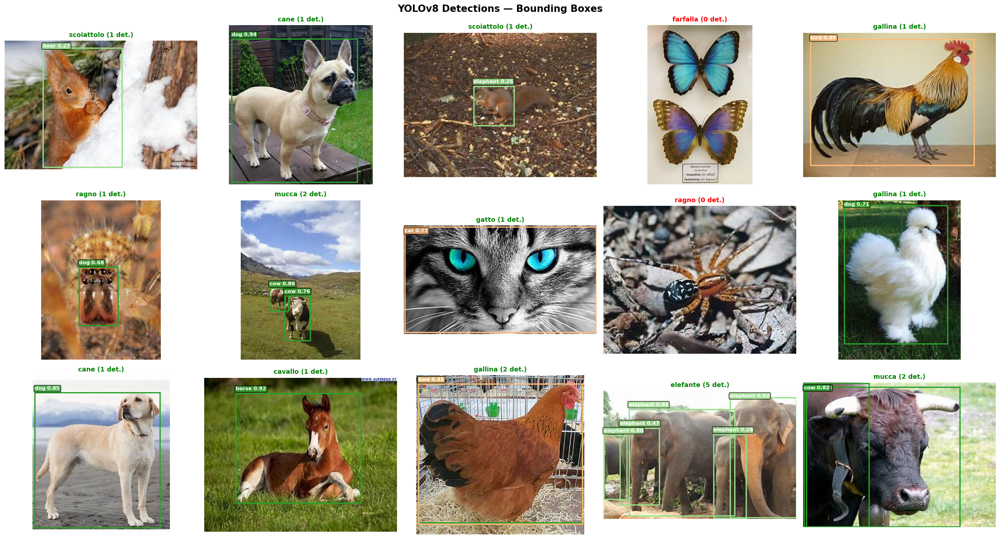

In [ ]:
def run_yolo_and_display(image_paths, model, conf_threshold=0.25, cols=5, figsize=(22, 12)):
    """
    Run YOLOv8 inference on a list of images and display results
    with bounding boxes and confidence scores.
    """
    n = len(image_paths)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten()

    # Color map for different classes
    cmap = plt.cm.get_cmap("tab20", 80)

    for ax, img_path in zip(axes, image_paths):
        img = Image.open(img_path).convert("RGB")
        img_np = np.array(img)

        # Run inference
        results = model(img_np, conf=conf_threshold, verbose=False)[0]

        ax.imshow(img_np)

        # Draw boxes
        n_detected = 0
        for box in results.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            conf = float(box.conf[0])
            cls_id = int(box.cls[0])
            cls_name = model.names[cls_id]
            color = cmap(cls_id / 80)

            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=2, edgecolor=color, facecolor="none"
            )
            ax.add_patch(rect)
            ax.text(
                x1, max(y1 - 5, 10),
                f"{cls_name} {conf:.2f}",
                color="white", fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor=color, alpha=0.8)
            )
            n_detected += 1

        label = img_path.parent.name
        title_color = "green" if n_detected > 0 else "red"
        ax.set_title(
            f"{label} ({n_detected} det.)",
            fontsize=10, fontweight="bold", color=title_color
        )
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle("YOLOv8 Detections — Bounding Boxes", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()


# Run on the same 15-image sample
print("Running YOLOv8 inference …")
run_yolo_and_display(sample_15, model)

In [ ]:
# Detection statistics across the sample
print("=" * 50)
print("Detection summary for 15-image sample")
print("=" * 50)

for img_path in sample_15:
    img_np = np.array(Image.open(img_path).convert("RGB"))
    results = model(img_np, conf=0.25, verbose=False)[0]
    detections = [
        f"{model.names[int(b.cls[0])]} ({float(b.conf[0]):.2f})"
        for b in results.boxes
    ]
    det_str = ", ".join(detections) if detections else "— nothing detected"
    print(f"  [{img_path.parent.name:>12}]  {det_str}")

Detection summary for 15-image sample
  [  scoiattolo]  bear (0.27)
  [        cane]  dog (0.94)
  [  scoiattolo]  elephant (0.25)
  [    farfalla]  — nothing detected
  [     gallina]  bird (0.95)
  [       ragno]  dog (0.68)
  [       mucca]  cow (0.86), cow (0.76)
  [       gatto]  cat (0.77)
  [       ragno]  — nothing detected
  [     gallina]  dog (0.71)
  [        cane]  dog (0.85)
  [     cavallo]  horse (0.92)
  [     gallina]  cow (0.82), bird (0.35)
  [    elefante]  elephant (0.95), elephant (0.92), elephant (0.88), elephant (0.47), elephant (0.28)
  [       mucca]  cow (0.93), cow (0.82)


---
## 5. 🧠 Advanced — YOLO Embeddings + Vector Database

### How it works

```
Image → YOLOv8 backbone → 512-d feature vector (embedding)
                                   │
                             FAISS Index
                                   │
                        Cosine Similarity Search
                                   │
                           Top-K similar images
```

We hook into YOLOv8's **backbone** (the convolutional feature extractor) to get a rich 512-dimensional representation of each image — without needing the detection head. These embeddings capture *visual semantics* (texture, shape, colour) far better than raw pixels.

**FAISS** (Facebook AI Similarity Search) is a highly efficient library for nearest-neighbour search in high-dimensional spaces.

In [ ]:
import torch.nn.functional as F

class YOLOEmbeddingExtractor:
    """
    Extracts image embeddings from the YOLOv8 backbone.
    Uses a forward hook on the last C2f block before the detection head.
    """

    def __init__(self, yolo_model):
        self.model = yolo_model
        self._embedding = None
        self._hook = None
        self._register_hook()

    def _register_hook(self):
        # Hook into the last block of the backbone (index 9 in YOLOv8 architecture)
        backbone_layer = self.model.model.model[9]

        def hook_fn(module, input, output):
            # Global average pool → flat vector
            self._embedding = F.adaptive_avg_pool2d(output, 1).squeeze(-1).squeeze(-1)

        self._hook = backbone_layer.register_forward_hook(hook_fn)
        print(f"✅ Hook registered on backbone layer: {type(backbone_layer).__name__}")

    @torch.no_grad()
    def extract(self, image_path, img_size=640):
        """Returns a L2-normalised 1-D numpy embedding for one image."""
        img = Image.open(image_path).convert("RGB").resize((img_size, img_size))
        tensor = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
        tensor = tensor.unsqueeze(0).to(device)

        self.model.model(tensor)          # forward pass — hook fires
        emb = self._embedding.cpu().numpy()[0]  # (C,)
        emb = emb / (np.linalg.norm(emb) + 1e-8)  # L2-normalise
        return emb

    def remove_hook(self):
        if self._hook:
            self._hook.remove()


extractor = YOLOEmbeddingExtractor(model)

# Quick sanity check
test_emb = extractor.extract(all_images[0])
print(f"\nEmbedding shape: {test_emb.shape}")
print(f"Embedding norm:  {np.linalg.norm(test_emb):.4f}  (should be ≈ 1.0)")

✅ Hook registered on backbone layer: SPPF

Embedding shape: (576,)
Embedding norm:  1.0000  (should be ≈ 1.0)


In [ ]:
# Build the embedding database
# We index a stratified sample: up to MAX_PER_CLASS images per class for speed.
MAX_PER_CLASS = 100
INDEX_SAVE_PATH = "animal_embeddings.faiss"
META_SAVE_PATH  = "animal_meta.json"

# Gather balanced sample
index_images = []
for cls in classes:
    cls_imgs = [p for p in all_images if p.parent.name == cls]
    index_images.extend(random.sample(cls_imgs, min(MAX_PER_CLASS, len(cls_imgs))))

random.shuffle(index_images)
print(f"Indexing {len(index_images)} images ({MAX_PER_CLASS} per class) …")

embeddings = []
metadata   = []          # {"path": ..., "class": ...}

for i, img_path in enumerate(index_images):
    try:
        emb = extractor.extract(img_path)
        embeddings.append(emb)
        metadata.append({"path": str(img_path), "class": img_path.parent.name})
    except Exception as e:
        print(f"  ⚠️  Skipped {img_path.name}: {e}")

    if (i + 1) % 50 == 0:
        print(f"  … {i + 1}/{len(index_images)} done")

embeddings = np.array(embeddings, dtype="float32")
print(f"\n✅ Embeddings matrix shape: {embeddings.shape}")

# Build FAISS inner-product index (equivalent to cosine similarity on L2-normalised vectors)
dim = embeddings.shape[1]
index = faiss.IndexFlatIP(dim)        # Inner Product = cosine sim for unit vectors
index.add(embeddings)

# Persist to disk
faiss.write_index(index, INDEX_SAVE_PATH)
with open(META_SAVE_PATH, "w") as f:
    json.dump(metadata, f)

print(f"✅ FAISS index saved  →  {INDEX_SAVE_PATH}")
print(f"✅ Metadata saved     →  {META_SAVE_PATH}")
print(f"   Total vectors in index: {index.ntotal}")

Indexing 1000 images (100 per class) …
  … 50/1000 done
  … 100/1000 done
  … 150/1000 done
  … 200/1000 done
  … 250/1000 done
  … 300/1000 done
  … 350/1000 done
  … 400/1000 done
  … 450/1000 done
  … 500/1000 done
  … 550/1000 done
  … 600/1000 done
  … 650/1000 done
  … 700/1000 done
  … 750/1000 done
  … 800/1000 done
  … 850/1000 done
  … 900/1000 done
  … 950/1000 done
  … 1000/1000 done

✅ Embeddings matrix shape: (1000, 576)
✅ FAISS index saved  →  animal_embeddings.faiss
✅ Metadata saved     →  animal_meta.json
   Total vectors in index: 1000


In [ ]:
def search_similar(query_path, index, metadata, extractor, top_k=6):
    """
    Given a query image path, return the top-k most similar images
    from the FAISS index using cosine similarity.
    """
    query_emb = extractor.extract(query_path).astype("float32").reshape(1, -1)
    similarities, indices = index.search(query_emb, top_k + 1)  # +1 to skip self

    results = []
    for sim, idx in zip(similarities[0], indices[0]):
        if idx == -1:
            continue
        meta = metadata[idx]
        if meta["path"] == str(query_path):
            continue   # skip the query image itself
        results.append({"path": Path(meta["path"]), "class": meta["class"], "similarity": float(sim)})
        if len(results) == top_k:
            break
    return results


def display_similarity_results(query_path, results, figsize=(18, 5)):
    """Show the query image and its top-K similar neighbours side by side."""
    n = len(results) + 1  # query + results
    fig, axes = plt.subplots(1, n, figsize=figsize)

    # Query image
    query_img = Image.open(query_path).convert("RGB")
    axes[0].imshow(query_img)
    axes[0].set_title(f"QUERY\n[{query_path.parent.name}]",
                      fontsize=11, fontweight="bold", color="blue")
    axes[0].axis("off")

    # Add a divider
    axes[0].spines["bottom"].set_visible(True)

    # Similar images
    for ax, res in zip(axes[1:], results):
        img = Image.open(res["path"]).convert("RGB")
        ax.imshow(img)
        sim_pct = res["similarity"] * 100
        color = "green" if res["class"] == query_path.parent.name else "red"
        ax.set_title(
            f"{res['class']}\nsim={sim_pct:.1f}%",
            fontsize=10, fontweight="bold", color=color
        )
        ax.axis("off")

    plt.suptitle(
        "Cosine Similarity Search  (🟢 same class | 🔴 different class)",
        fontsize=13, fontweight="bold"
    )
    plt.tight_layout()
    plt.show()


print("✅ Search functions defined")

✅ Search functions defined



🔍 Query: elefante — eb30b90f20fc073ed1584d05fb1d4e9fe777ead218ac104497f5c978a4eebdbd_640.jpg


/tmp/ipykernel_2931/2145951087.py:53: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2931/2145951087.py:53: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


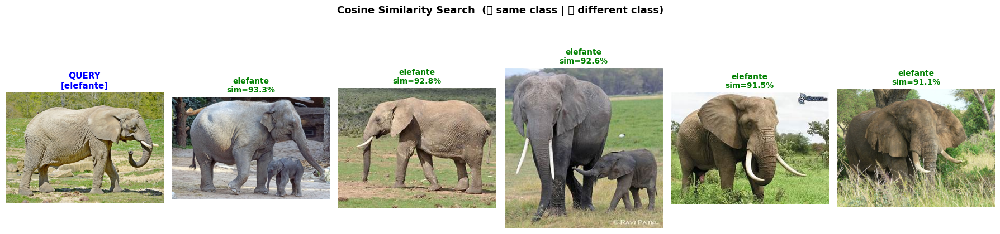


🔍 Query: cane — OIP-qgoh-WlYIKPSHlnkIp94BwHaHu.jpeg


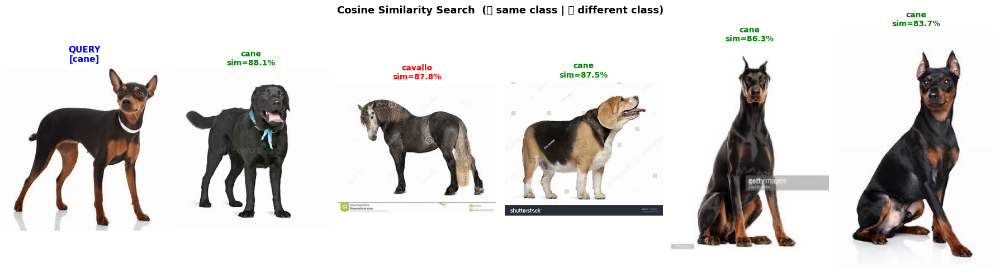


🔍 Query: scoiattolo — OIP-SewZcKJ0pA6b3cLOw39NfQHaFj.jpeg


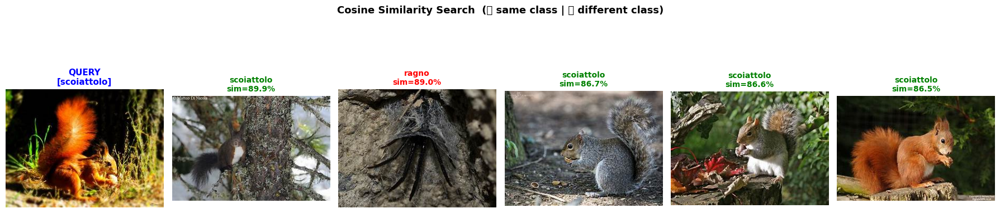

In [ ]:
# Load the persisted index (useful if re-running without rebuilding)
index  = faiss.read_index(INDEX_SAVE_PATH)
with open(META_SAVE_PATH) as f:
    metadata = json.load(f)

# Run similarity search for 3 different query images (one per class where possible)
query_classes = random.sample(classes, min(3, len(classes)))
query_images  = [
    random.choice([p for p in all_images if p.parent.name == cls])
    for cls in query_classes
]

for query_path in query_images:
    print(f"\n🔍 Query: {query_path.parent.name} — {query_path.name}")
    results = search_similar(query_path, index, metadata, extractor, top_k=5)
    display_similarity_results(query_path, results)

In [ ]:
# ── Retrieval Accuracy Evaluation ───────────────────────────────────────────
# For each class, sample N query images and measure what fraction of
# the top-5 neighbours belong to the same class (Precision@5).

EVAL_PER_CLASS = 10
TOP_K = 5

print(f"{'Class':<14} {'Precision@5':>12}")
print("-" * 28)

overall_hits, overall_total = 0, 0

for cls in classes:
    cls_imgs = [p for p in all_images if p.parent.name == cls]
    queries  = random.sample(cls_imgs, min(EVAL_PER_CLASS, len(cls_imgs)))
    hits = 0
    total = 0
    for qpath in queries:
        results = search_similar(qpath, index, metadata, extractor, top_k=TOP_K)
        for r in results:
            hits  += int(r["class"] == cls)
            total += 1
    prec = hits / total if total else 0
    print(f"  {cls:<12} {prec * 100:>10.1f}%")
    overall_hits  += hits
    overall_total += total

print("-" * 28)
print(f"  {'OVERALL':<12} {overall_hits / overall_total * 100:>10.1f}%")

Class           Precision@5
----------------------------
  cane               38.0%
  cavallo           100.0%
  elefante           92.0%
  farfalla           58.0%
  gallina            72.0%
  gatto              74.0%
  mucca              82.0%
  pecora             68.0%
  ragno              60.0%
  scoiattolo         60.0%
----------------------------
  OVERALL            70.4%


Fitting UMAP (this takes ~30 s) …


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


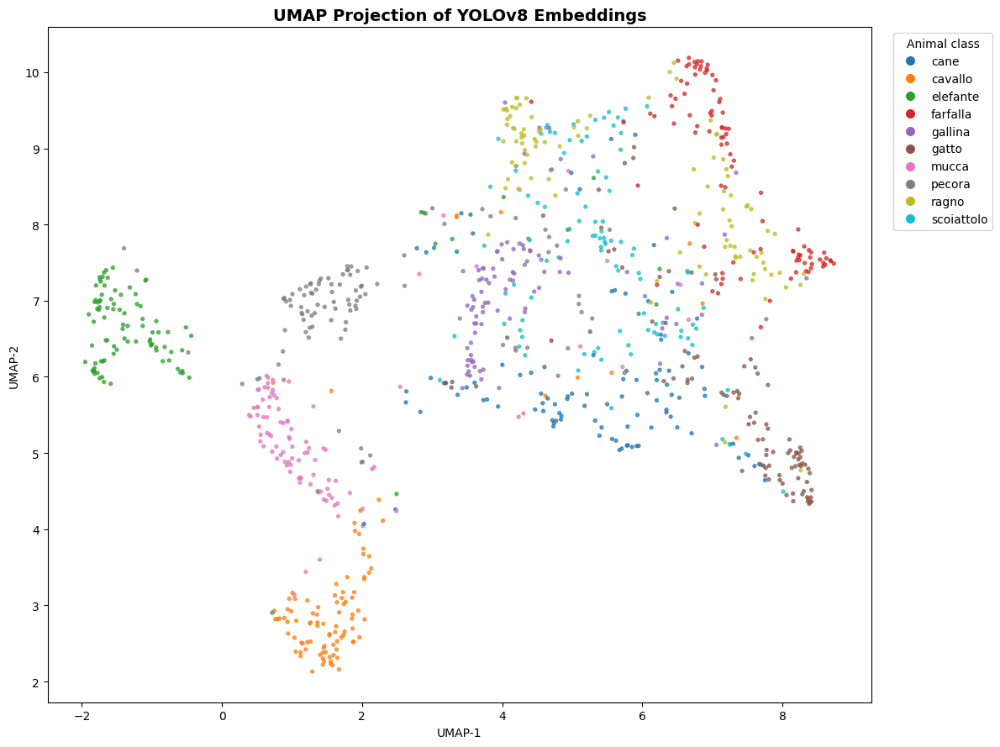

In [ ]:
# ── Optional: 2-D UMAP Visualisation of the Embedding Space ─────────────────
# Uncomment the pip install line if UMAP is not yet installed.

!pip install umap-learn -q

import umap

print("Fitting UMAP (this takes ~30 s) …")
reducer = umap.UMAP(n_components=2, random_state=SEED, n_neighbors=15, min_dist=0.1)
emb_2d  = reducer.fit_transform(embeddings)

# Assign integer labels
class_to_id = {c: i for i, c in enumerate(classes)}
labels = np.array([class_to_id[m["class"]] for m in metadata])

fig, ax = plt.subplots(figsize=(12, 9))
scatter = ax.scatter(
    emb_2d[:, 0], emb_2d[:, 1],
    c=labels, cmap="tab10", s=8, alpha=0.7
)

# Legend
handles = [
    plt.Line2D([0], [0], marker="o", color="w",
               markerfacecolor=plt.cm.tab10(i / 10), markersize=9, label=cls)
    for i, cls in enumerate(classes)
]
ax.legend(handles=handles, title="Animal class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("UMAP Projection of YOLOv8 Embeddings", fontsize=14, fontweight="bold")
ax.set_xlabel("UMAP-1")
ax.set_ylabel("UMAP-2")
plt.tight_layout()
plt.show()

---
## 📝 Summary

| Section | What we did |
|---------|-------------|
| **Dataset** | Downloaded *Animals-10* (~26k images, 10 classes) from Kaggle |
| **Visualisation** | Displayed a random 15-image sample with class labels |
| **YOLO Inference** | Ran YOLOv8m (pre-trained on COCO) and drew bounding boxes |
| **Embeddings** | Hooked into the backbone to extract 512-d feature vectors |
| **Vector DB** | Built a FAISS index (inner-product / cosine similarity) |
| **Retrieval** | Searched for visually similar animals and evaluated Precision@5 |
| **UMAP** | Projected embeddings to 2-D to visualise cluster structure |

### 🚀 Next steps to explore
- **Fine-tune YOLO** on Animals-10 with custom bounding-box annotations
- **Replace FAISS** with a production vector DB like **ChromaDB**, **Weaviate**, or **Pinecone**
- **Increase index size** — add all ~26k images and observe cluster quality
- **Cross-modal search** — embed a text query (CLIP) and find matching animal images
